In [1]:
library(googledrive)

In [2]:
# Authenticate using the browser-based instructions
drive_auth(use_oob = TRUE)

Is it OK to cache OAuth access credentials in the folder ~/.cache/gargle
between R sessions?
1: Yes
2: No


Selection: 1


Please point your browser to the following url: 

https://accounts.google.com/o/oauth2/v2/auth?client_id=603366585132-frjlouoa3s2ono25d2l9ukvhlsrlnr7k.apps.googleusercontent.com&scope=https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fdrive%20https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fuserinfo.email&redirect_uri=https%3A%2F%2Fwww.tidyverse.org%2Fgoogle-callback%2F&response_type=code&state=1f5b678cd40eaa1d538120bd020edf11&access_type=offline&prompt=consent



Enter authorization code: eyJjb2RlIjoiNC8wQVVuNkhkLUdRT0R3RHpRdExCeTZkTEZuc2JLN3kyQnN0bVdQVmR2UEM5NTdRN0VmTzVwdEs1VmFXY3dzdlliVUsxOXNZUSIsInN0YXRlIjoiMWY1YjY3OGNkNDBlYWExZDUzODEyMGJkMDIwZWRmMTEifQ==


In [3]:
folder_url <- "https://drive.google.com/drive/u/0/folders/165-U0WK69Vugf9rlT7z1sUoerY3bIU7-"

project_folder <- drive_get(as_id(folder_url))

folder_files <- drive_ls(project_folder)

print(folder_files)

# A dribble: 5 × 3
  name                 id                                drive_resource   
  <chr>                <drv_id>                          <list>           
1 Topic_8_R.ipynb      1w95vvIUFar3iK47aFEDFe0L_VxqlVSd_ <named list [47]>
2 Topic_8.pdf          13WR3QZerJFHYYP8CIRoyudpOIndg59mF <named list [46]>
3 Topic_8_Python.ipynb 1I4zrER9nMPGMWUJpSEZ1QVx8APyLN-9_ <named list [47]>
4 winequality-red.csv  19clMnK9lRPwG3o_yXt-YxQBdQ5LCogIG <named list [46]>
5 house_data.csv       1Ttj1ULZ5xYqZC09O740uKDdHi14Z8s8C <named list [45]>


In [4]:
dataset_file <- folder_files[
  folder_files$name == "winequality-red.csv",
]

drive_download(
  dataset_file,
  path = "winequality-red.csv",
  overwrite = TRUE
)

df <- read.csv(
  "winequality-red.csv",
  check.names = FALSE,
  stringsAsFactors = FALSE
)

cat(
  "Dataset loaded:",
  nrow(df), "rows,",
  ncol(df), "columns\n"
)

head(df)

File downloaded:

• winequality-red.csv <id: 19clMnK9lRPwG3o_yXt-YxQBdQ5LCogIG>

Saved locally as:

• winequality-red.csv



Dataset loaded: 1599 rows, 12 columns


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,7.4,0.70,0.00,1.9,0.076,11,34,0.9978,3.51,0.56,9.4,5
2,7.8,0.88,0.00,2.6,0.098,25,67,0.9968,3.20,0.68,9.8,5
3,7.8,0.76,0.04,2.3,0.092,15,54,0.9970,3.26,0.65,9.8,5
4,11.2,0.28,0.56,1.9,0.075,17,60,0.9980,3.16,0.58,9.8,6
5,7.4,0.70,0.00,1.9,0.076,11,34,0.9978,3.51,0.56,9.4,5
6,7.4,0.66,0.00,1.8,0.075,13,40,0.9978,3.51,0.56,9.4,5


                     fixed acidity volatile acidity citric acid residual sugar
fixed acidity                 1.00            -0.26        0.67           0.11
volatile acidity             -0.26             1.00       -0.55           0.00
citric acid                   0.67            -0.55        1.00           0.14
residual sugar                0.11             0.00        0.14           1.00
chlorides                     0.09             0.06        0.20           0.06
free sulfur dioxide          -0.15            -0.01       -0.06           0.19
total sulfur dioxide         -0.11             0.08        0.04           0.20
density                       0.67             0.02        0.36           0.36
pH                           -0.68             0.23       -0.54          -0.09
sulphates                     0.18            -0.26        0.31           0.01
alcohol                      -0.06            -0.20        0.11           0.04
                     chlorides free sulfur dioxide t

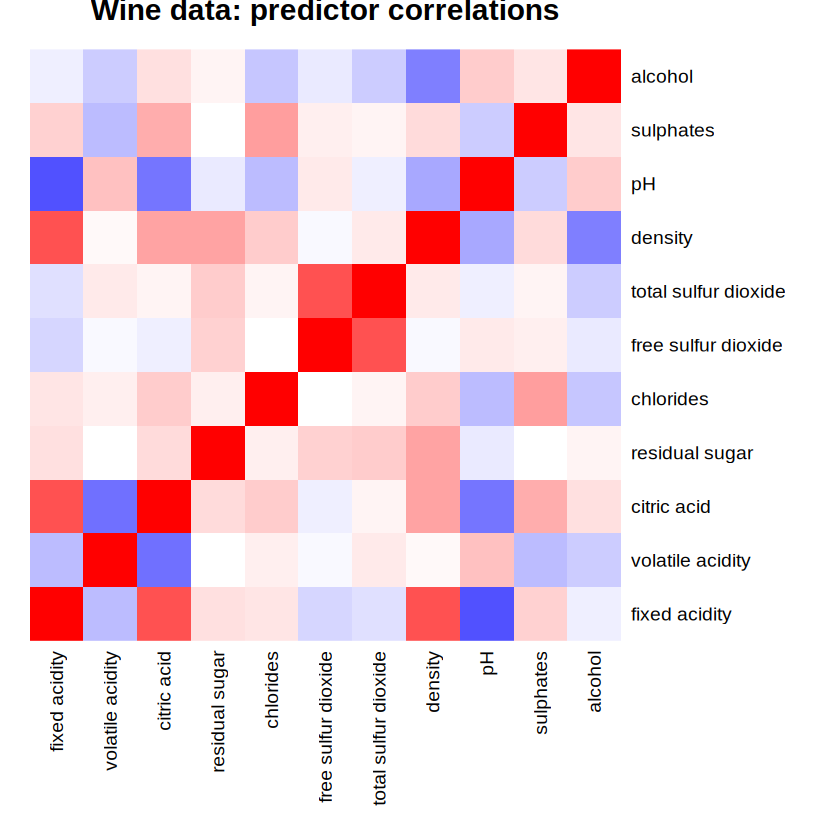

In [5]:
# Separate predictors and target
X <- df[, names(df) != "quality"]
y <- df$quality

# Calculate predictor correlations
correlation <- cor(X)

# Display the correlation matrix
print(round(correlation, 2))

# Plot the correlation matrix
heatmap(
  correlation,
  Rowv = NA,
  Colv = NA,
  scale = "none",
  col = colorRampPalette(c("blue", "white", "red"))(101),
  breaks = seq(-1, 1, length.out = 102),
  margins = c(10, 10),
  main = "Wine data: predictor correlations"
)

In [6]:
# Remove exact duplicate rows
data <- df[!duplicated(df), ]
rownames(data) <- NULL

# Separate predictors and target
X <- data[, names(data) != "quality"]
y <- factor(data$quality)

# Create a stratified training/test split
set.seed(42)

train_index <- unlist(
  lapply(
    split(seq_len(nrow(data)), y),
    function(index) sample(index, floor(0.8 * length(index)))
  ),
  use.names = FALSE
)

X_train <- X[train_index, ]
X_test <- X[-train_index, ]

y_train <- y[train_index]
y_test <- y[-train_index]

# Learn scaling parameters from training data only
X_train_scaled <- scale(X_train)

X_test_scaled <- scale(
  X_test,
  center = attr(X_train_scaled, "scaled:center"),
  scale = attr(X_train_scaled, "scaled:scale")
)

cat("Rows after removing duplicates:", nrow(data), "\n")
cat("Training shape:", dim(X_train_scaled), "\n")
cat("Test shape:", dim(X_test_scaled), "\n")

cat("\nTraining class counts:\n")
print(table(y_train))

cat("\nTest class counts:\n")
print(table(y_test))

Rows after removing duplicates: 1359 
Training shape: 1085 11 
Test shape: 274 11 

Training class counts:
y_train
  3   4   5   6   7   8 
  8  42 461 428 133  13 

Test class counts:
y_test
  3   4   5   6   7   8 
  2  11 116 107  34   4 


In [7]:
# Install the Random Forest package if needed
if (!requireNamespace("ranger", quietly = TRUE)) {
  install.packages("ranger", repos = "https://cloud.r-project.org")
}

library(ranger)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘RcppEigen’




In [8]:
# Train the baseline model using all predictors
start <- proc.time()[["elapsed"]]

rf_baseline <- ranger(
  x = as.data.frame(X_train_scaled),
  y = y_train,
  num.trees = 300,
  mtry = ncol(X_train_scaled),
  seed = 42
)

baseline_time <- proc.time()[["elapsed"]] - start

# Predict test classes
pred_baseline <- predict(
  rf_baseline,
  data = as.data.frame(X_test_scaled)
)$predictions

# Calculate the confusion matrix
cm <- table(
  Actual = y_test,
  Predicted = factor(pred_baseline, levels = levels(y_test))
)

print(cm)

# Calculate class-wise precision and recall
precision <- diag(cm) / colSums(cm)
recall <- diag(cm) / rowSums(cm)

precision[is.na(precision)] <- 0
recall[is.na(recall)] <- 0

# Calculate class-wise F1
class_f1 <- 2 * precision * recall / (precision + recall)
class_f1[is.na(class_f1)] <- 0

# Store test results
results <- data.frame(
  Model = "Baseline RF",
  Inputs = ncol(X_train_scaled),
  Accuracy = sum(diag(cm)) / sum(cm),
  Balanced_accuracy = mean(recall),
  Macro_F1 = mean(class_f1),
  RF_fit_time_seconds = baseline_time
)

print(results)

      Predicted
Actual  3  4  5  6  7  8
     3  0  0  2  0  0  0
     4  0  0  7  4  0  0
     5  0  0 89 26  1  0
     6  0  0 33 68  6  0
     7  0  0  6 13 14  1
     8  0  0  0  2  2  0
        Model Inputs  Accuracy Balanced_accuracy  Macro_F1 RF_fit_time_seconds
1 Baseline RF     11 0.6240876           0.30242 0.3021612               0.746


   Component Explained_variance Cumulative_variance
1          1              0.286               0.286
2          2              0.174               0.460
3          3              0.144               0.604
4          4              0.112               0.716
5          5              0.086               0.802
6          6              0.057               0.859
7          7              0.052               0.911
8          8              0.037               0.948
9          9              0.030               0.978
10        10              0.016               0.994
11        11              0.006               1.000

Maximum PCA transformation difference: 0 
Retained components: 7 
Retained variance: 0.911 
Training shape: 1085 7 
Test shape: 274 7 


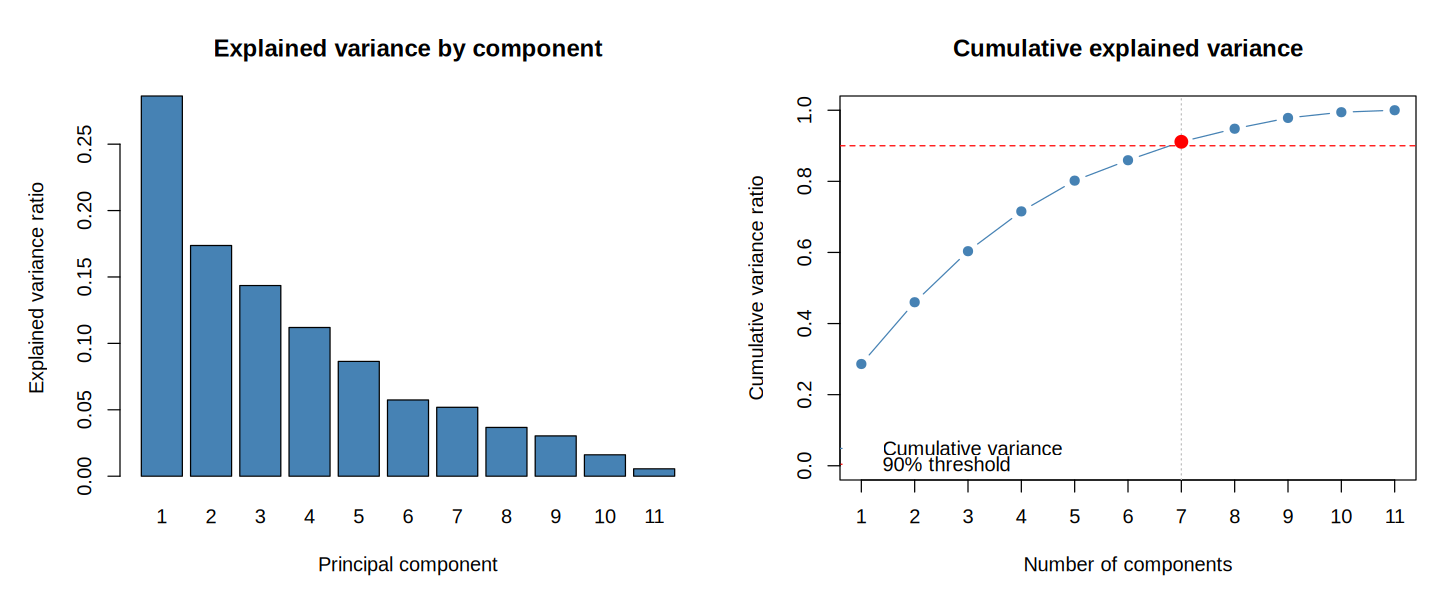

In [9]:
# Fit scaling and PCA on the original training predictors
pca <- prcomp(
  X_train,
  center = TRUE,
  scale. = TRUE
)

# Apply the learned transformation to test data
Z_train_all <- pca$x
Z_test_all <- predict(pca, newdata = X_test)

# Calculate individual and cumulative explained variance
variance <- pca$sdev^2 / sum(pca$sdev^2)
cumulative <- cumsum(variance)
components <- seq_along(variance)

# Retain at least 90% of the training variance
threshold <- 0.90
k <- which(cumulative >= threshold)[1]

Z_train <- Z_train_all[, seq_len(k), drop = FALSE]
Z_test <- Z_test_all[, seq_len(k), drop = FALSE]

# Display the explained-variance table
print(round(data.frame(
  Component = components,
  Explained_variance = variance,
  Cumulative_variance = cumulative
), 3))

# Verify that the training transformation is consistent
Z_train_check <- predict(pca, newdata = X_train)

cat(
  "\nMaximum PCA transformation difference:",
  max(abs(Z_train_check - pca$x)),
  "\n"
)

cat("Retained components:", k, "\n")
cat("Retained variance:", round(cumulative[k], 3), "\n")
cat("Training shape:", dim(Z_train), "\n")
cat("Test shape:", dim(Z_test), "\n")

# Display two plots side by side
options(repr.plot.width = 12, repr.plot.height = 5)
old_par <- par(mfrow = c(1, 2), mar = c(5, 5, 4, 1))

# Plot the variance explained by each component
barplot(
  variance,
  names.arg = components,
  col = "steelblue",
  main = "Explained variance by component",
  xlab = "Principal component",
  ylab = "Explained variance ratio"
)

# Plot cumulative explained variance
plot(
  components,
  cumulative,
  type = "b",
  pch = 19,
  col = "steelblue",
  ylim = c(0, 1),
  xaxt = "n",
  main = "Cumulative explained variance",
  xlab = "Number of components",
  ylab = "Cumulative variance ratio"
)

axis(1, at = components)

abline(h = threshold, col = "red", lty = 2)
abline(v = k, col = "grey", lty = 3)

points(k, cumulative[k], pch = 19, col = "red", cex = 1.4)

legend(
  "bottomright",
  legend = c("Cumulative variance", "90% threshold"),
  col = c("steelblue", "red"),
  lty = c(1, 2),
  bty = "n"
)

par(old_par)

In [10]:
# Train Random Forest using PCA components
start <- proc.time()[["elapsed"]]

rf_pca <- ranger(
  x = as.data.frame(Z_train),
  y = y_train,
  num.trees = 300,
  mtry = ncol(Z_train),
  seed = 42
)

pca_time <- proc.time()[["elapsed"]] - start

# Predict test classes
pred_pca <- predict(
  rf_pca,
  data = as.data.frame(Z_test)
)$predictions

# Calculate the confusion matrix
cm_pca <- table(
  Actual = y_test,
  Predicted = factor(pred_pca, levels = levels(y_test))
)

print(cm_pca)

# Calculate class-wise precision and recall
precision <- diag(cm_pca) / colSums(cm_pca)
recall <- diag(cm_pca) / rowSums(cm_pca)

precision[is.na(precision)] <- 0
recall[is.na(recall)] <- 0

# Calculate class-wise F1
class_f1 <- 2 * precision * recall / (precision + recall)
class_f1[is.na(class_f1)] <- 0

# Store PCA results
pca_result <- data.frame(
  Model = "PCA + RF",
  Inputs = ncol(Z_train),
  Accuracy = sum(diag(cm_pca)) / sum(cm_pca),
  Balanced_accuracy = mean(recall),
  Macro_F1 = mean(class_f1),
  RF_fit_time_seconds = pca_time
)

# Replace the previous PCA row if this cell is rerun
results <- rbind(
  results[results$Model != "PCA + RF", ],
  pca_result
)

print(results)

      Predicted
Actual  3  4  5  6  7  8
     3  1  0  1  0  0  0
     4  0  1  6  4  0  0
     5  0  1 81 33  1  0
     6  0  1 36 60 10  0
     7  0  0  3 20 10  1
     8  0  0  0  2  2  0
        Model Inputs  Accuracy Balanced_accuracy  Macro_F1 RF_fit_time_seconds
1 Baseline RF     11 0.6240876         0.3024200 0.3021612               0.746
2    PCA + RF      7 0.5583942         0.3573417 0.3930069               1.389


In [11]:
# Install the regularised modelling package if needed
if (!requireNamespace("glmnet", quietly = TRUE)) {
  install.packages("glmnet", repos = "https://cloud.r-project.org")
}

library(glmnet)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘iterators’, ‘foreach’, ‘shape’


Loading required package: Matrix

Loaded glmnet 5.2



Warning message in .resolve_control(control = control, nvars = nvars, deprecated = list(thresh = if (!missing(thresh)) thresh, :
“Passing 'maxit' to glmnet() is deprecated. Use control = list(maxit = ...) instead.”


                                  Feature Maximum_absolute_coefficient Selected
fixed acidity               fixed acidity                   0.06539463     TRUE
volatile acidity         volatile acidity                   0.54439386     TRUE
citric acid                   citric acid                   0.00000000    FALSE
residual sugar             residual sugar                   0.00000000    FALSE
chlorides                       chlorides                   0.01329747     TRUE
free sulfur dioxide   free sulfur dioxide                   0.00000000    FALSE
total sulfur dioxide total sulfur dioxide                   0.34861420     TRUE
density                           density                   0.00000000    FALSE
pH                                     pH                   0.00000000    FALSE
sulphates                       sulphates                   0.18743535     TRUE
alcohol                           alcohol                   0.70916333     TRUE

Selected features: fixed acidity volati

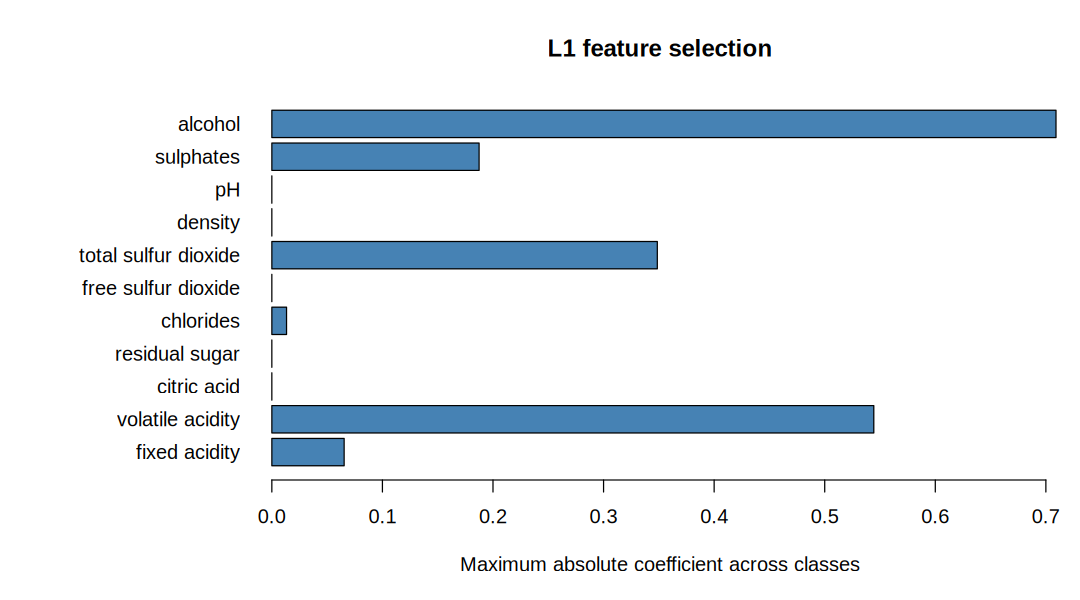

In [12]:
# Fit an L1-regularised classification model
# Predictors have already been standardised
selector_l1 <- glmnet(
  x = X_train_scaled,
  y = y_train,
  family = "multinomial",
  alpha = 1,
  lambda = 0.025,
  standardize = FALSE,
  maxit = 100000
)

# Extract coefficients for each class
class_coefficients <- coef(selector_l1, s = 0.01)

# Combine feature coefficients, excluding intercepts
coefficient_matrix <- do.call(
  cbind,
  lapply(
    class_coefficients,
    function(x) as.matrix(x)[-1, 1]
  )
)

# Measure each feature's largest absolute coefficient across classes
importance_l1 <- apply(abs(coefficient_matrix), 1, max)

# Retain features active in at least one class
selected_l1 <- importance_l1 > 1e-6
features_l1 <- colnames(X_train_scaled)[selected_l1]

# Apply the same feature subset to both datasets
X_train_l1 <- X_train_scaled[, selected_l1, drop = FALSE]
X_test_l1 <- X_test_scaled[, selected_l1, drop = FALSE]

# Display coefficients and selection
selection_table <- data.frame(
  Feature = colnames(X_train_scaled),
  Maximum_absolute_coefficient = importance_l1,
  Selected = selected_l1
)

print(selection_table)

cat("\nSelected features:", features_l1, "\n")
cat("Retained feature count:", length(features_l1), "\n")

# Plot coefficient magnitudes
options(repr.plot.width = 9, repr.plot.height = 5)
old_par <- par(mar = c(5, 11, 4, 1))

barplot(
  importance_l1,
  names.arg = colnames(X_train_scaled),
  horiz = TRUE,
  las = 1,
  col = "steelblue",
  main = "L1 feature selection",
  xlab = "Maximum absolute coefficient across classes"
)

par(old_par)

In [13]:
# Train Random Forest using L1-selected features
start <- proc.time()[["elapsed"]]

rf_l1 <- ranger(
  x = as.data.frame(X_train_l1),
  y = y_train,
  num.trees = 300,
  mtry = ncol(X_train_l1),
  seed = 42
)

l1_time <- proc.time()[["elapsed"]] - start

# Predict test classes
pred_l1 <- predict(
  rf_l1,
  data = as.data.frame(X_test_l1)
)$predictions

# Calculate the confusion matrix
cm_l1 <- table(
  Actual = y_test,
  Predicted = factor(pred_l1, levels = levels(y_test))
)

print(cm_l1)

# Calculate class-wise precision and recall
precision <- diag(cm_l1) / colSums(cm_l1)
recall <- diag(cm_l1) / rowSums(cm_l1)

precision[is.na(precision)] <- 0
recall[is.na(recall)] <- 0

# Calculate class-wise F1
class_f1 <- 2 * precision * recall / (precision + recall)
class_f1[is.na(class_f1)] <- 0

# Store evaluation results
l1_result <- data.frame(
  Model = "L1 selection + RF",
  Inputs = ncol(X_train_l1),
  Accuracy = sum(diag(cm_l1)) / sum(cm_l1),
  Balanced_accuracy = mean(recall),
  Macro_F1 = mean(class_f1),
  RF_fit_time_seconds = l1_time
)

# Update the comparison table
results <- rbind(
  results[results$Model != "L1 selection + RF", ],
  l1_result
)

print(results)

      Predicted
Actual  3  4  5  6  7  8
     3  0  0  2  0  0  0
     4  0  0  7  4  0  0
     5  0  1 94 21  0  0
     6  0  0 36 62  9  0
     7  0  0  2 18 13  1
     8  0  0  0  1  3  0
              Model Inputs  Accuracy Balanced_accuracy  Macro_F1
1       Baseline RF     11 0.6240876         0.3024200 0.3021612
2          PCA + RF      7 0.5583942         0.3573417 0.3930069
3 L1 selection + RF      6 0.6167883         0.2953562 0.2923925
  RF_fit_time_seconds
1               0.746
2               1.389
3               0.457


                                  Feature Maximum_absolute_coefficient Selected
fixed acidity               fixed acidity                   0.03982560     TRUE
volatile acidity         volatile acidity                   0.33680947     TRUE
citric acid                   citric acid                   0.05500471     TRUE
residual sugar             residual sugar                   0.00000000    FALSE
chlorides                       chlorides                   0.02787839     TRUE
free sulfur dioxide   free sulfur dioxide                   0.00000000    FALSE
total sulfur dioxide total sulfur dioxide                   0.31968936     TRUE
density                           density                   0.00000000    FALSE
pH                                     pH                   0.00000000    FALSE
sulphates                       sulphates                   0.18030868     TRUE
alcohol                           alcohol                   0.61563719     TRUE

Selected features: fixed acidity volati

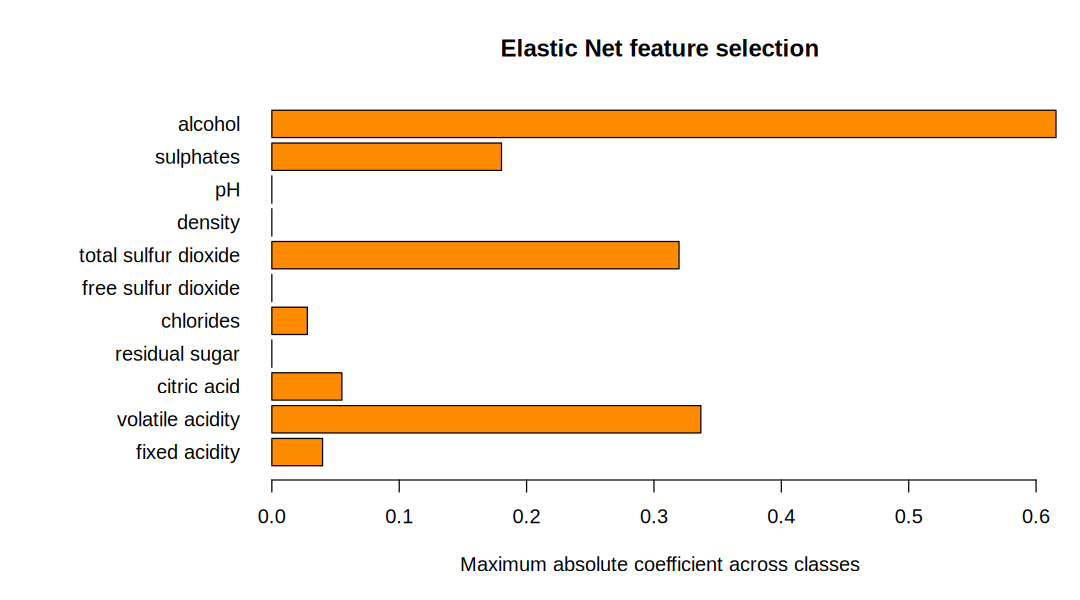

In [14]:
# Set the regularisation parameters
lambda_en <- 0.05
mixing_ratio <- 0.5

# Fit an Elastic Net classification model
selector_en <- glmnet(
  x = X_train_scaled,
  y = y_train,
  family = "multinomial",
  alpha = mixing_ratio,
  lambda = lambda_en,
  standardize = FALSE,
  maxit = 100000
)

# Extract coefficients for each class
class_coefficients_en <- coef(selector_en, s = lambda_en)

# Combine feature coefficients, excluding intercepts
coefficient_matrix_en <- do.call(
  cbind,
  lapply(
    class_coefficients_en,
    function(x) as.matrix(x)[-1, 1]
  )
)

# Measure coefficient magnitudes across classes
importance_en <- apply(abs(coefficient_matrix_en), 1, max)

# Select active features
selected_en <- importance_en > 1e-6
features_en <- colnames(X_train_scaled)[selected_en]

# Apply the same subset to training and test data
X_train_en <- X_train_scaled[, selected_en, drop = FALSE]
X_test_en <- X_test_scaled[, selected_en, drop = FALSE]

# Display the selection results
selection_table_en <- data.frame(
  Feature = colnames(X_train_scaled),
  Maximum_absolute_coefficient = importance_en,
  Selected = selected_en
)

print(selection_table_en)

cat("\nSelected features:", features_en, "\n")
cat("Retained feature count:", length(features_en), "\n")

# Plot coefficient magnitudes
options(repr.plot.width = 9, repr.plot.height = 5)
old_par <- par(mar = c(5, 11, 4, 1))

barplot(
  importance_en,
  names.arg = colnames(X_train_scaled),
  horiz = TRUE,
  las = 1,
  col = "darkorange",
  main = "Elastic Net feature selection",
  xlab = "Maximum absolute coefficient across classes"
)

par(old_par)

In [15]:
# Train Random Forest using Elastic Net-selected features
start <- proc.time()[["elapsed"]]

rf_en <- ranger(
  x = as.data.frame(X_train_en),
  y = y_train,
  num.trees = 300,
  mtry = ncol(X_train_en),
  seed = 42
)

en_time <- proc.time()[["elapsed"]] - start

# Predict test classes
pred_en <- predict(
  rf_en,
  data = as.data.frame(X_test_en)
)$predictions

# Calculate the confusion matrix
cm_en <- table(
  Actual = y_test,
  Predicted = factor(pred_en, levels = levels(y_test))
)

print(cm_en)

# Calculate class-wise precision and recall
precision <- diag(cm_en) / colSums(cm_en)
recall <- diag(cm_en) / rowSums(cm_en)

precision[is.na(precision)] <- 0
recall[is.na(recall)] <- 0

# Calculate class-wise F1
class_f1 <- 2 * precision * recall / (precision + recall)
class_f1[is.na(class_f1)] <- 0

# Store evaluation results
en_result <- data.frame(
  Model = "Elastic Net selection + RF",
  Inputs = ncol(X_train_en),
  Accuracy = sum(diag(cm_en)) / sum(cm_en),
  Balanced_accuracy = mean(recall),
  Macro_F1 = mean(class_f1),
  RF_fit_time_seconds = en_time
)

# Update the comparison table
results <- rbind(
  results[results$Model != "Elastic Net selection + RF", ],
  en_result
)

print(results)

      Predicted
Actual  3  4  5  6  7  8
     3  0  0  2  0  0  0
     4  0  0  6  5  0  0
     5  0  1 88 26  1  0
     6  0  0 34 65  8  0
     7  0  0  3 16 14  1
     8  0  0  0  1  3  0
                       Model Inputs  Accuracy Balanced_accuracy  Macro_F1
1                Baseline RF     11 0.6240876         0.3024200 0.3021612
2                   PCA + RF      7 0.5583942         0.3573417 0.3930069
3          L1 selection + RF      6 0.6167883         0.2953562 0.2923925
4 Elastic Net selection + RF      7 0.6094891         0.2963103 0.2940672
  RF_fit_time_seconds
1               0.746
2               1.389
3               0.457
4               0.488


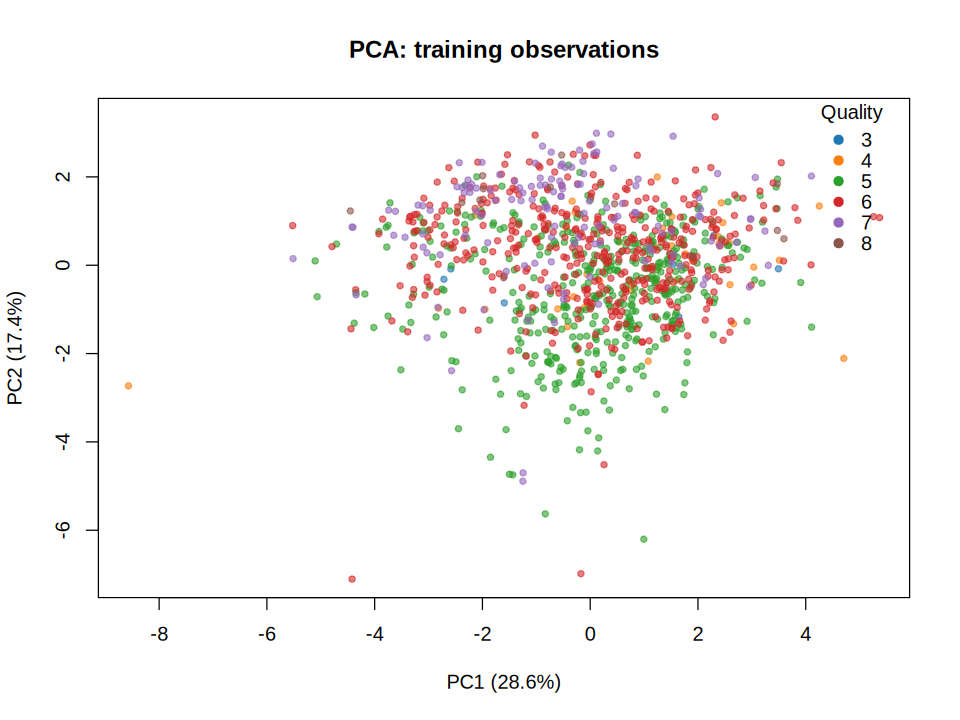

In [16]:
# Assign a consistent colour to each quality class
class_colours <- c(
  "3" = "#1f77b4", "4" = "#ff7f0e",
  "5" = "#2ca02c", "6" = "#d62728",
  "7" = "#9467bd", "8" = "#8c564b"
)

point_colours <- adjustcolor(
  class_colours[as.character(y_train)],
  alpha.f = 0.6
)

# Plot the first two principal components
options(repr.plot.width = 8, repr.plot.height = 6)

plot(
  Z_train_all[, 1],
  Z_train_all[, 2],
  col = point_colours,
  pch = 19,
  cex = 0.7,
  xlab = sprintf("PC1 (%.1f%%)", 100 * variance[1]),
  ylab = sprintf("PC2 (%.1f%%)", 100 * variance[2]),
  main = "PCA: training observations"
)

legend(
  "topright",
  legend = levels(y_train),
  col = class_colours[levels(y_train)],
  pch = 19,
  title = "Quality",
  bty = "n"
)

In [17]:
# Install the t-SNE package if needed
if (!requireNamespace("Rtsne", quietly = TRUE)) {
  install.packages("Rtsne", repos = "https://cloud.r-project.org")
}

library(Rtsne)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



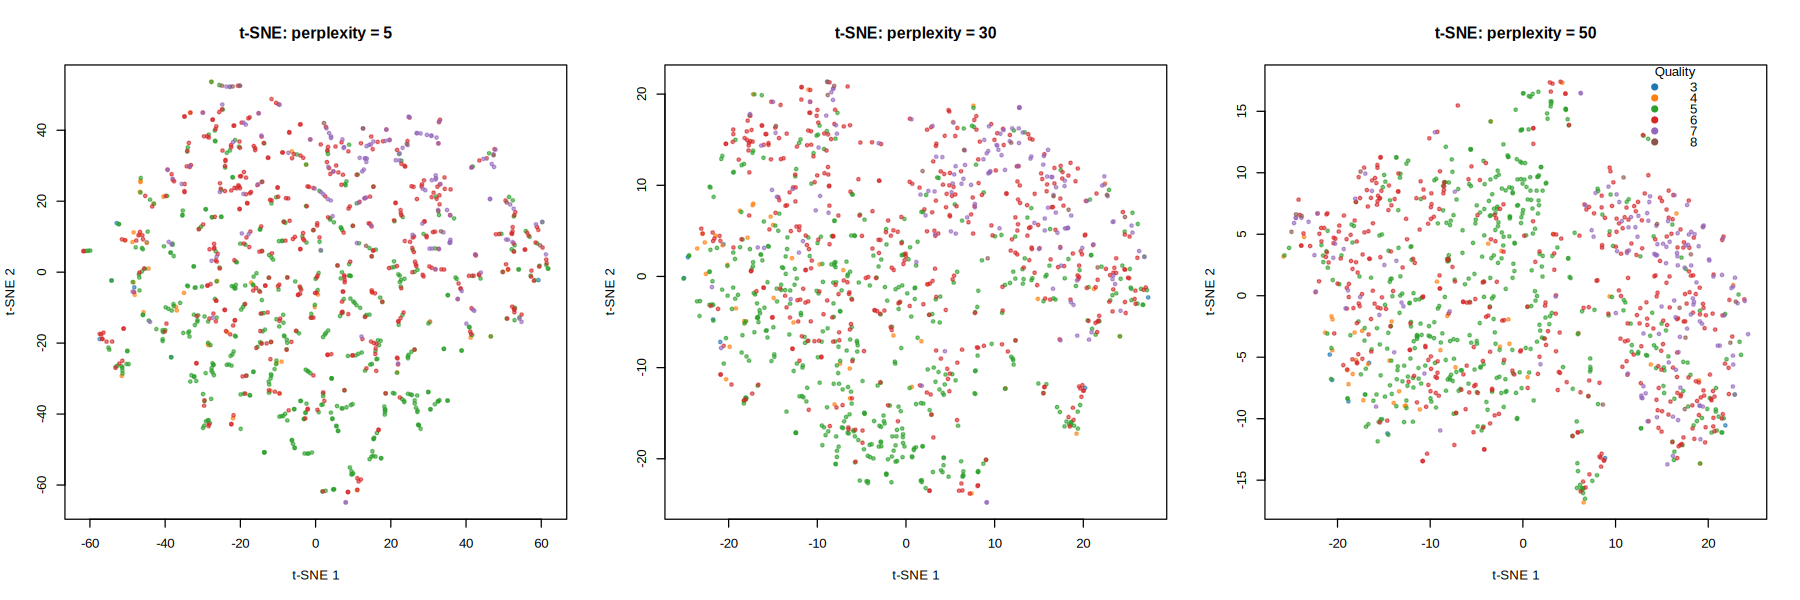

In [18]:
# Compare neighbourhood scales using the same observations
perplexities <- c(5, 30, 50)
tsne_embeddings <- list()

options(repr.plot.width = 15, repr.plot.height = 5)
old_par <- par(mfrow = c(1, 3))

for (perplexity in perplexities) {
  set.seed(42)

  tsne <- Rtsne(
    X_train_scaled,
    dims = 2,
    perplexity = perplexity,
    pca = FALSE,
    normalize = FALSE,
    check_duplicates = FALSE,
    eta = 200,
    max_iter = 1000,
    verbose = FALSE
  )

  embedding <- tsne$Y
  tsne_embeddings[[as.character(perplexity)]] <- embedding

  plot(
    embedding,
    col = point_colours,
    pch = 19,
    cex = 0.6,
    main = paste("t-SNE: perplexity =", perplexity),
    xlab = "t-SNE 1",
    ylab = "t-SNE 2"
  )
}

legend(
  "topright",
  legend = levels(y_train),
  col = class_colours[levels(y_train)],
  pch = 19,
  title = "Quality",
  bty = "n"
)

par(old_par)

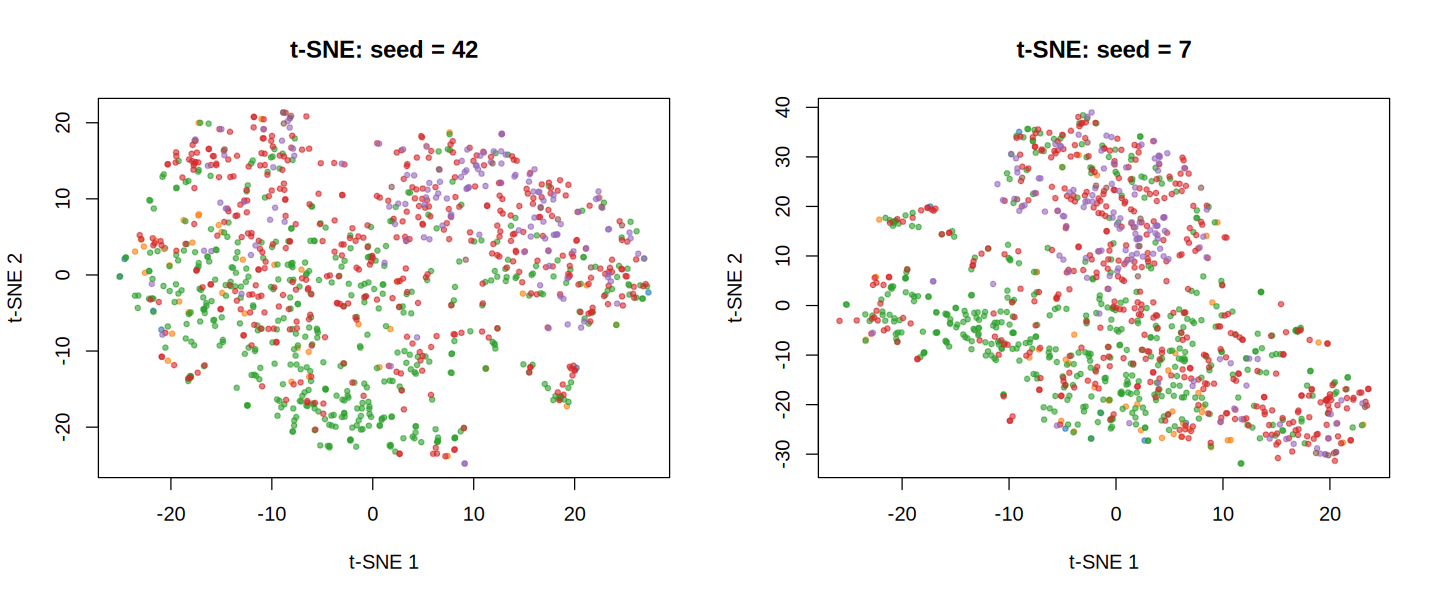

In [19]:
# Repeat the perplexity-30 embedding with another seed
set.seed(7)

tsne_seed7 <- Rtsne(
  X_train_scaled,
  dims = 2,
  perplexity = 30,
  pca = FALSE,
  normalize = FALSE,
  check_duplicates = FALSE,
  eta = 200,
  max_iter = 1000,
  verbose = FALSE
)$Y

options(repr.plot.width = 12, repr.plot.height = 5)
old_par <- par(mfrow = c(1, 2))

plot(
  tsne_embeddings[["30"]],
  col = point_colours, pch = 19, cex = 0.6,
  main = "t-SNE: seed = 42",
  xlab = "t-SNE 1", ylab = "t-SNE 2"
)

plot(
  tsne_seed7,
  col = point_colours, pch = 19, cex = 0.6,
  main = "t-SNE: seed = 7",
  xlab = "t-SNE 1", ylab = "t-SNE 2"
)

par(old_par)

In [20]:
# Install the UMAP package if needed
if (!requireNamespace("uwot", quietly = TRUE)) {
  install.packages("uwot", repos = "https://cloud.r-project.org")
}

library(uwot)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘BH’, ‘sitmo’, ‘FNN’, ‘irlba’, ‘RcppAnnoy’, ‘RSpectra’, ‘dqrng’, ‘RcppProgress’




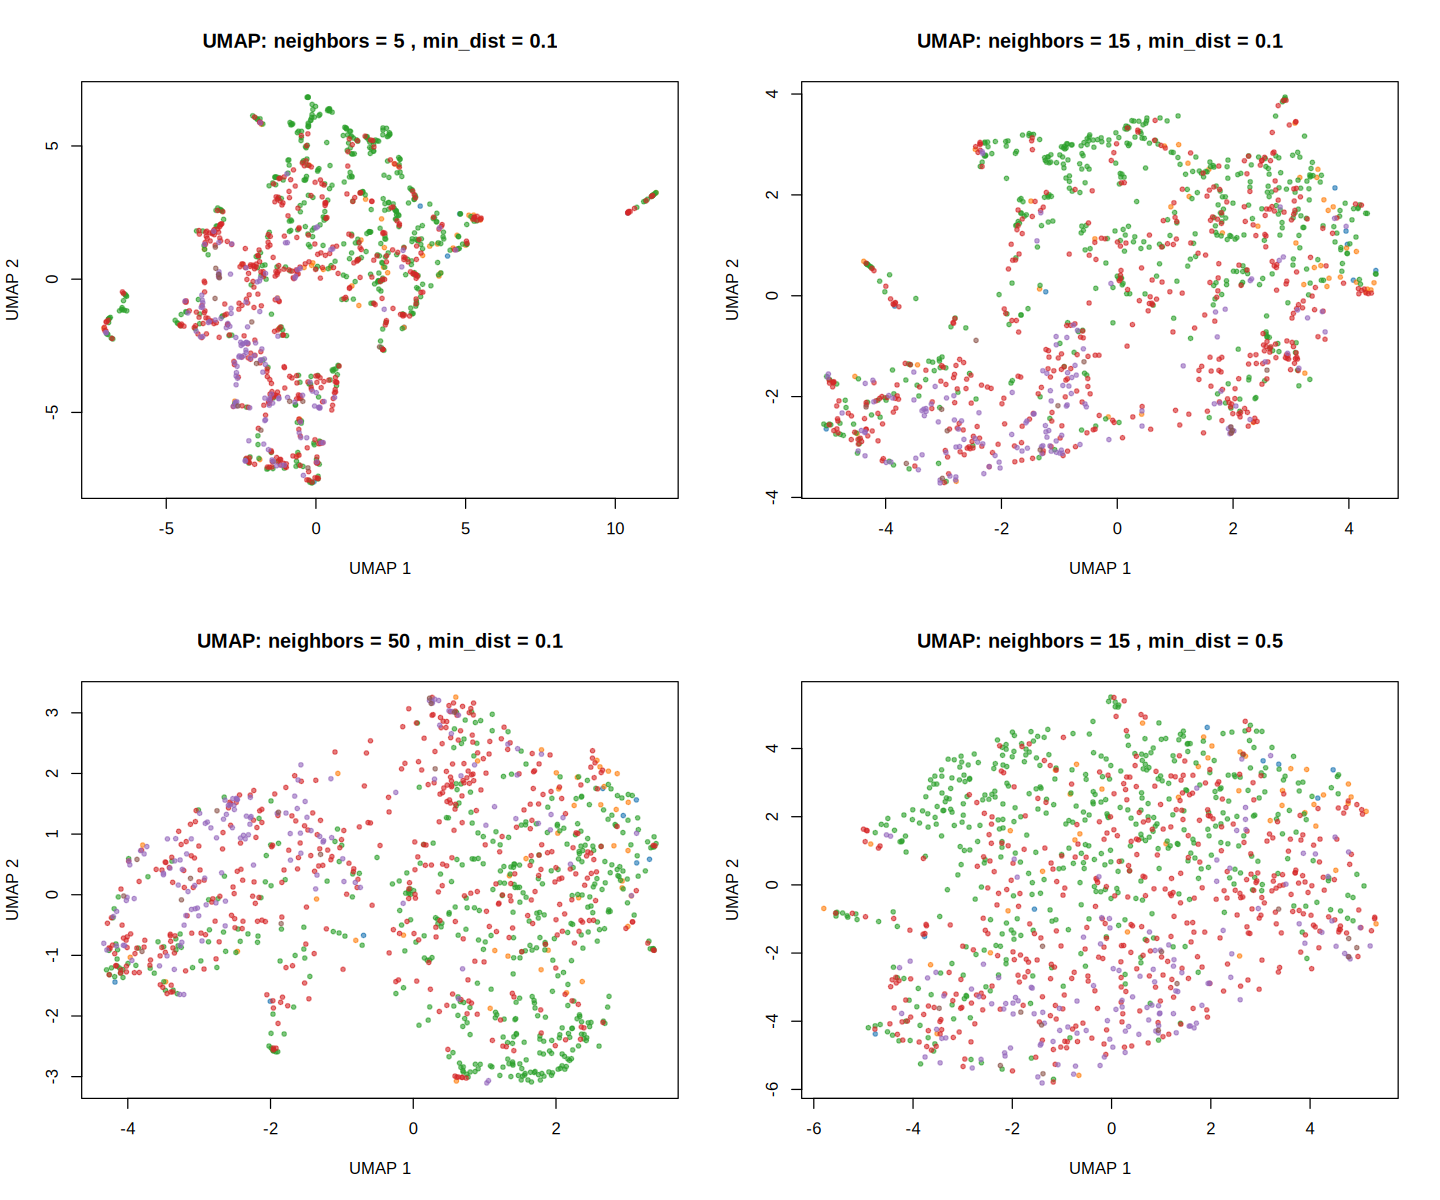

In [21]:
# Compare neighbourhood size and minimum distance
settings <- data.frame(
  neighbors = c(5, 15, 50, 15),
  distance = c(0.1, 0.1, 0.1, 0.5)
)

umap_embeddings <- list()

options(repr.plot.width = 12, repr.plot.height = 10)
old_par <- par(mfrow = c(2, 2))

for (i in seq_len(nrow(settings))) {
  set.seed(42)

  embedding <- umap(
    X_train_scaled,
    n_components = 2,
    n_neighbors = settings$neighbors[i],
    min_dist = settings$distance[i],
    metric = "euclidean",
    n_threads = 1,
    n_sgd_threads = 1,
    verbose = FALSE
  )

  umap_embeddings[[i]] <- embedding

  plot(
    embedding,
    col = point_colours,
    pch = 19,
    cex = 0.6,
    main = paste(
      "UMAP: neighbors =", settings$neighbors[i],
      ", min_dist =", settings$distance[i]
    ),
    xlab = "UMAP 1",
    ylab = "UMAP 2"
  )
}

par(old_par)